# 01 · Deep Learning Foundations: from scikit-learn MLPs to PyTorch

**Module:** Deep Learning Architectures for Protein–Protein Interactions
**Builds on:** NIGMS Sandbox *Protein-Protein Interactions using ML*, Submodules 2 & 3

## Overview

In the NIGMS module you trained a random forest, a logistic regression and a scikit-learn multi-layer perceptron (MLP) to tell **SARS-CoV** apart from **SARS-CoV-2** using molecular dynamics (MD) frames of each receptor-binding domain (RBD) bound to human ACE2. Each frame is a vector of **4,886 inverse distances** between pairs of interface residues, and the models' feature importances pointed to the residues that make SARS-CoV-2 bind more tightly.

This series asks a sequence of follow-up questions. Each new architecture was invented because the previous one could not answer a question well:

| Notebook | Architecture | The question it answers | The limitation that motivates the next step |
|---|---|---|---|
| **01** (this one) | Deep MLP in PyTorch, gradient attribution | *Which features separate the two variants?* | A classifier models $p(y \mid x)$ only; it cannot describe or generate conformations |
| 02 | Autoencoder → Variational Autoencoder | *What is the shape of the conformational landscape? Can we sample it?* | Gaussian likelihood gives blurry, over-smoothed samples |
| 03 | GAN → Wasserstein GAN (+ conditioning) | *Can we produce sharp, realistic samples?* | Adversarial training is unstable and drops modes |
| 04 | Denoising Diffusion (DDPM, DDIM, guidance) | *Can we get quality **and** coverage with stable training?* | Every model so far sees the interface as a flat vector and ignores which residues pair |
| 05 | Attention & Transformers | *Which residues talk to which partners?* | — combine with generation → |
| 06 | Diffusion Transformer + modern landscape | *How do AlphaFold 3, RFdiffusion and ESM fit into this story?* | |

## Learning objectives

1. Understand why the train/test split must respect the time-correlation of MD frames.
2. Rebuild the Submodule-3 MLP in PyTorch and write an explicit training loop (forward pass, loss, back-propagation, optimizer step).
3. Use validation curves, dropout and weight decay to control over-fitting.
4. Compute per-residue importance with **gradient saliency** and **integrated gradients**, and compare them with linear-model coefficients.
5. Articulate what a discriminative model *cannot* tell us, which sets up generative modelling.

## Prerequisites

Python, NumPy, and the concepts from NIGMS Submodule 2 (train/test splits, logistic regression, MLPs). No GPU is required; this notebook runs in about 2 minutes on a laptop CPU.

## Get started
Install the requirements once (`pip install -r requirements.txt`). The helper package `ppi_dl` downloads the four NIGMS MD feature files (~78 MB) on first use. If you already cloned the NIGMS repository, set `PPI_DATA_DIR` to its `tutorial_files/ML_input_files` folder to skip the download.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, ".")          # run this notebook from the ppi_deep_learning/ folder
from ppi_dl.data import load_ppi, load_runs, load_interface, set_seed, get_device
from ppi_dl.plotting import plot_residue_importance, top_residues

set_seed(0)
device = get_device()
print("torch", torch.__version__, "| device:", device)

torch 2.14.1 | device: cpu


## 1. The data, revisited

Each MD frame records a distance (nm) for every ACE2–RBD residue pair that comes within 1.5 nm
during the simulation. (The NIGMS module distributes these as residue–residue distances; the
values go down to 0.24 nm, too short for C$\alpha$–C$\alpha$ contacts, so they are closest-atom
rather than backbone distances.) As in Submodule 3, we use the **inverse** distance $1/d$, so close contacts get large values, then standardize each feature to zero mean and unit variance.

The interface involves **233 ACE2 residues** and **156 RBD residues**, but only 4,886 of the $233 \times 156$ possible pairs are ever in contact. We can place a frame back onto that grid to view it as a contact map. Notebooks 05–06 will exploit this residue structure directly.

cov1 run 1: 1000 frames x 4886 pair distances
cov1 run 2: 1000 frames x 4886 pair distances
cov2 run 1: 1000 frames x 4886 pair distances
cov2 run 2: 1000 frames x 4886 pair distances
interface: 233 ACE2 residues x 156 RBD residues, 4886 pairs measured


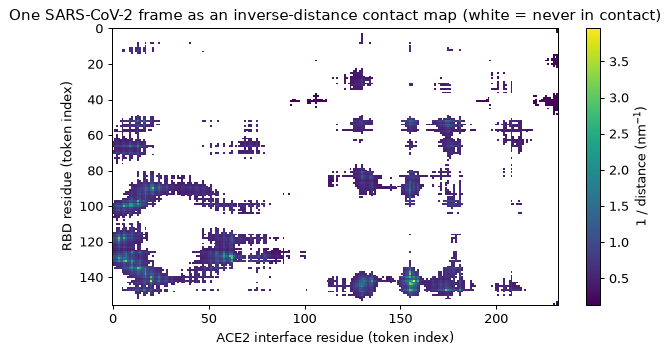

In [2]:
runs = load_runs()
iface = load_interface()
for (variant, run), arr in runs.items():
    print(f"{variant} run {run}: {arr.shape[0]} frames x {arr.shape[1]} pair distances")
print(f"interface: {iface.n_ace2} ACE2 residues x {iface.n_rbd} RBD residues, {len(iface.pair_ace2_idx)} pairs measured")

frame = runs[("cov2", 1)][0]
M, mask = iface.to_pair_matrix((1.0 / frame)[None], fill=np.nan)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(M[0].T, aspect="auto", cmap="viridis", interpolation="nearest")
ax.set_xlabel("ACE2 interface residue (token index)")
ax.set_ylabel("RBD residue (token index)")
ax.set_title("One SARS-CoV-2 frame as an inverse-distance contact map (white = never in contact)")
fig.colorbar(im, ax=ax, label="1 / distance (nm$^{-1}$)")
plt.show()

## 2. Why the train/test split matters for MD data

Consecutive MD frames are snapshots taken a short time apart, so frame $t$ and frame $t+1$ are almost identical. If we shuffle all frames and split randomly (as Submodule 3 does), nearly every test frame has a near-copy in the training set. The test score then measures memory, not generalization.

Let us measure how long the "memory" of a trajectory lasts, using the autocorrelation of the first principal component.

autocorrelation drops below 0.5 after 8 frames


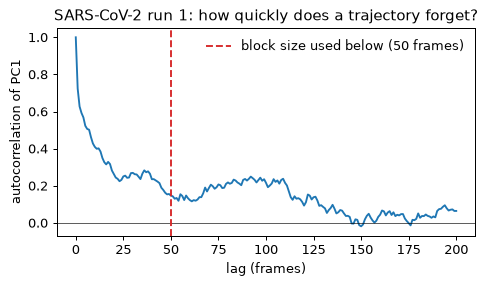

In [3]:
from sklearn.decomposition import PCA

traj = 1.0 / runs[("cov2", 1)]
pc1 = PCA(1).fit_transform((traj - traj.mean(0)) / traj.std(0))[:, 0]
pc1 = (pc1 - pc1.mean()) / pc1.std()
lags = np.arange(0, 201)
acf = [1.0] + [np.corrcoef(pc1[:-k], pc1[k:])[0, 1] for k in lags[1:]]

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(lags, acf)
ax.axhline(0, color="k", lw=0.5)
ax.axvline(50, color="tab:red", ls="--", label="block size used below (50 frames)")
ax.set_xlabel("lag (frames)"); ax.set_ylabel("autocorrelation of PC1")
ax.set_title("SARS-CoV-2 run 1: how quickly does a trajectory forget?")
ax.legend(frameon=False)
plt.show()
first_below = int(np.argmax(np.array(acf) < 0.5))
print(f"autocorrelation drops below 0.5 after {first_below} frames")

The `ppi_dl` loader offers three splits:

* **`random`**: shuffle all 4,000 frames, hold out 20% (Submodule 3's approach).
* **`block`**: cut each trajectory into 50-frame blocks and hold out every 5th block. Train and test come from the same simulations, but near-duplicate neighbours rarely straddle the split. **We use this for the rest of the series.**
* **`run`**: train on run 1, test on the independent run 2. This is the strictest test: do the learned patterns transfer to a separate simulation?

In [4]:
from sklearn.linear_model import LogisticRegression

rows = []
for split in ["random", "block", "run"]:
    d = load_ppi(split)
    lr = LogisticRegression(C=0.01, max_iter=3000).fit(d.X_train, d.y_train)
    rows.append({"split": split, "n_train": len(d.y_train), "n_test": len(d.y_test),
                 "train acc": lr.score(d.X_train, d.y_train), "test acc": lr.score(d.X_test, d.y_test)})
split_table = pd.DataFrame(rows).set_index("split").round(4)
split_table

,n_train,n_test,train acc,test acc
split,,,,
random,3200,800,1.0,1.0000
block,3200,800,1.0,1.0000
run,2000,2000,1.0,0.9915


**What to take away.** The two variants are *very* easy to tell apart. Even the strict `run` split gives near-perfect accuracy, because the RBD sequences differ and many pair distances shift systematically. Accuracy alone therefore cannot distinguish good models from bad ones here. The scientifically interesting output is **what the model relies on**, which is the focus of Section 4. The split still matters: with `random` the test set is effectively a copy of the training set, so any over-fitting stays invisible.

## 3. Rebuilding the MLP in PyTorch

scikit-learn's `MLPClassifier.fit()` hides the whole optimization. PyTorch makes each part explicit, and every model in this series (VAEs, GANs, diffusion models, transformers) is trained with the same five-line loop:

```python
for xb, yb in loader:              # 1. take a minibatch
    logits = model(xb)             # 2. forward pass
    loss = loss_fn(logits, yb)     # 3. compare with targets
    optimizer.zero_grad()
    loss.backward()                # 4. back-propagate: d loss / d every weight
    optimizer.step()               # 5. update weights
```

Only the **model** and the **loss** change between architectures. That is why it pays to learn the loop once, carefully.

In [5]:
data = load_ppi("block")
print(data.summary())

Xtr = torch.tensor(data.X_train); ytr = torch.tensor(data.y_train)
Xte = torch.tensor(data.X_test);  yte = torch.tensor(data.y_test)

class MLP(nn.Module):
    """Same shape as the Submodule-3 network, written explicitly."""
    def __init__(self, d_in, hidden=(256, 64), dropout=0.0, n_classes=2):
        super().__init__()
        layers, prev = [], d_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))   # raw scores (logits)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def train_classifier(model, X, y, Xval, yval, epochs=40, lr=1e-3, weight_decay=0.0, bs=64):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist["train_loss"].append(F.cross_entropy(model(X), y).item())
            out = model(Xval)
            hist["val_loss"].append(F.cross_entropy(out, yval).item())
            hist["val_acc"].append((out.argmax(1) == yval).float().mean().item())
    return hist

print(MLP(data.n_features))
print("trainable parameters:", sum(p.numel() for p in MLP(data.n_features).parameters()))

split=block: train (3200, 4886), test (800, 4886), train class counts [1600, 1600], test class counts [400, 400]
MLP(
  (net): Sequential(
    (0): Linear(in_features=4886, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)
trainable parameters: 1267650


### Over-fitting and regularization

The network has about **1.27 million parameters** but only 3,200 training frames. With that many free parameters it can memorize. To make this visible we use a harder setting: train on only 10% of the frames and validate on the independent run-2 trajectory, then compare an unregularized net with one that uses **dropout** (randomly zeroing hidden units during training) and **weight decay** (penalizing large weights).

trained both in 4.3s
final validation loss  plain: 0.149   regularized: 0.101


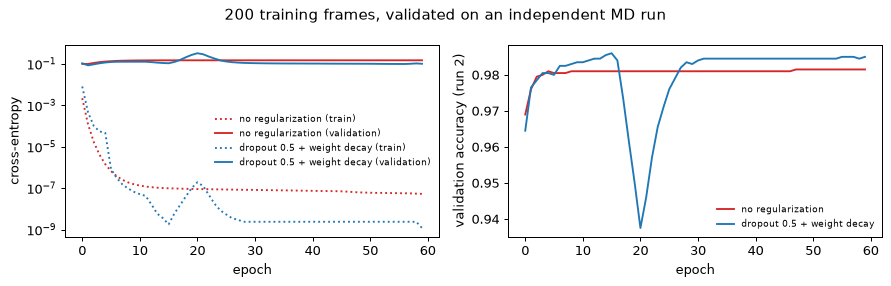

In [6]:
strict = load_ppi("run")
rng = np.random.default_rng(0)
sub = rng.choice(len(strict.y_train), 200, replace=False)
Xs, ys = torch.tensor(strict.X_train[sub]), torch.tensor(strict.y_train[sub])
Xv, yv = torch.tensor(strict.X_test), torch.tensor(strict.y_test)

t0 = time.time()
set_seed(0); h_plain = train_classifier(MLP(strict.n_features), Xs, ys, Xv, yv, epochs=60)
set_seed(0); h_reg = train_classifier(MLP(strict.n_features, dropout=0.5), Xs, ys, Xv, yv,
                                      epochs=60, weight_decay=0.1)
print(f"trained both in {time.time()-t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for h, name, c in [(h_plain, "no regularization", "tab:red"), (h_reg, "dropout 0.5 + weight decay", "tab:blue")]:
    axes[0].plot(h["train_loss"], c=c, ls=":", label=f"{name} (train)")
    axes[0].plot(h["val_loss"], c=c, label=f"{name} (validation)")
    axes[1].plot(h["val_acc"], c=c, label=name)
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy (run 2)")
axes[0].legend(fontsize=7, frameon=False); axes[1].legend(fontsize=7, frameon=False)
fig.suptitle("200 training frames, validated on an independent MD run")
fig.tight_layout(); plt.show()
print("final validation loss  plain: %.3f   regularized: %.3f" % (h_plain["val_loss"][-1], h_reg["val_loss"][-1]))

Look at the **gap** between training and validation loss. On the training frames both networks become essentially certain (cross-entropy around $10^{-7}$–$10^{-9}$), yet on the independent run their loss stays near $10^{-1}$. Because this task is so easy, over-fitting does not show up as a collapse in accuracy (both stay around 98%). It shows up as **over-confidence**: the network is far more certain than it has any right to be on new data. Regularization lowers the validation loss somewhat, though the curve is bumpier. On harder problems, such as the generative models that follow, this gap is often the first warning sign. Monitoring a validation loss, not just accuracy, is the habit to build.

Now we train the model we will interpret, on the full block split.

In [7]:
set_seed(0)
model = MLP(data.n_features, dropout=0.3)
hist = train_classifier(model, Xtr, ytr, Xte, yte, epochs=30, weight_decay=1e-2)
print(f"block split: final test accuracy {hist['val_acc'][-1]:.4f}")

block split: final test accuracy 1.0000


## 4. Opening the black box: which residue pairs does the network use?

Submodule 3 extracted MLP importances with **layer-wise relevance propagation (LRP)**. Here we use two gradient-based methods that work for *any* differentiable model, including the transformers in Notebook 05.

**Gradient saliency.** How much does the output change if we nudge feature $x_i$?
$$ S_i(x) = \left|\frac{\partial f(x)}{\partial x_i}\right| $$
where $f(x)$ is the logit difference $\text{logit}_{\text{CoV-2}} - \text{logit}_{\text{CoV}}$.

**Integrated gradients** (Sundararajan *et al.*, 2017). Gradients describe only an infinitesimal neighbourhood and can *saturate*. Integrated gradients instead accumulate gradients along a straight path from a **baseline** $x'$ (here the all-zeros vector, i.e. the average frame after standardization) to the input:
$$ \text{IG}_i(x) = (x_i - x'_i)\int_0^1 \frac{\partial f\big(x' + \alpha(x - x')\big)}{\partial x_i}\, d\alpha $$
IG satisfies *completeness*: the attributions sum to $f(x) - f(x')$.

We average the absolute attributions over test frames, then sum the pair scores onto residues (the Submodule-3 convention).

In [8]:
model.eval()
f = lambda x: model(x)[:, 1] - model(x)[:, 0]    # logit difference

def saliency(model, X):
    X = X.clone().requires_grad_(True)
    f(X).sum().backward()
    return X.grad.abs()

def integrated_gradients(model, X, steps=32, baseline=None):
    baseline = torch.zeros_like(X) if baseline is None else baseline
    total = torch.zeros_like(X)
    for a in torch.linspace(0, 1, steps + 1)[1:]:          # right Riemann sum
        Xa = (baseline + a * (X - baseline)).requires_grad_(True)
        f(Xa).sum().backward()
        total += Xa.grad
    return (X - baseline) * total / steps

sal = saliency(model, Xte).mean(0).numpy()
ig_raw = integrated_gradients(model, Xte)
ig = ig_raw.abs().mean(0).numpy()

with torch.no_grad():
    gap = (f(Xte) - f(torch.zeros_like(Xte))).numpy()
print("completeness check: corr(sum of IG, f(x) - f(baseline)) = %.4f"
      % np.corrcoef(ig_raw.sum(1).numpy(), gap)[0, 1])

lr = LogisticRegression(C=0.01, max_iter=3000).fit(data.X_train, data.y_train)
lr_coef = np.abs(lr.coef_[0])

completeness check: corr(sum of IG, f(x) - f(baseline)) = 1.0000


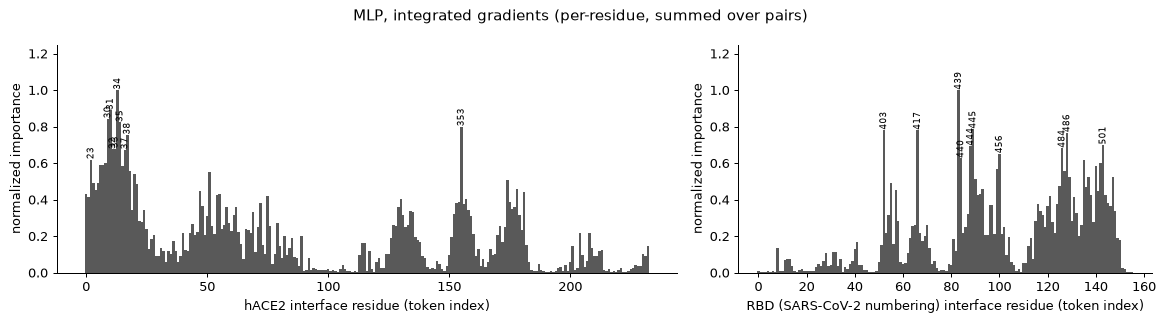

,ACE2 residue,ACE2 score,RBD residue (CoV-2 #),RBD score
0,34,1.000,439,1.000
1,31,0.889,445,0.787
2,30,0.843,403,0.782
3,35,0.823,417,0.781
4,353,0.800,486,0.768
5,38,0.754,501,0.701
6,33,0.680,444,0.693
7,32,0.675,484,0.682
8,37,0.674,456,0.652
9,23,0.620,440,0.627


In [9]:
fig, (ace_ig, rbd_ig) = plot_residue_importance(iface, ig, title="MLP, integrated gradients (per-residue, summed over pairs)")
plt.show()
ace_top, rbd_top = top_residues(iface, ig, k=10)
pd.DataFrame({"ACE2 residue": [r for r, _ in ace_top], "ACE2 score": [s for _, s in ace_top],
              "RBD residue (CoV-2 #)": [r for r, _ in rbd_top], "RBD score": [s for _, s in rbd_top]})

### Do different methods agree?

If several independent methods highlight the same features, we can trust the result more. We compare rankings with Spearman's rank correlation $\rho$, at two levels: the 4,886 individual **pairs**, and the 389 **residues** after summing.

In [10]:
from scipy.stats import spearmanr

methods = {"LR |coef|": lr_coef, "MLP saliency": sal, "MLP integrated grad.": ig}
names = list(methods)
def rho_table(scores):
    return pd.DataFrame([[spearmanr(scores[a], scores[b])[0] for b in names] for a in names],
                        index=names, columns=names).round(2)

res_scores = {k: np.concatenate(iface.residue_importance(v)) for k, v in methods.items()}
display(rho_table(methods).rename_axis("PAIR level (4,886)"))
display(rho_table(res_scores).rename_axis("RESIDUE level (389)"))

,LR |coef|,MLP saliency,MLP integrated grad.
"PAIR level (4,886)",,,
LR |coef|,1.00,0.83,0.83
MLP saliency,0.83,1.00,0.98
MLP integrated grad.,0.83,0.98,1.00


,LR |coef|,MLP saliency,MLP integrated grad.
RESIDUE level (389),,,
LR |coef|,1.00,0.98,0.98
MLP saliency,0.98,1.00,1.00
MLP integrated grad.,0.98,1.00,1.00


Agreement is much higher at the residue level than at the pair level. Part of that is genuine: different methods pick different pairs around the same residue. Part of it is an **artifact of summing**: a residue involved in many pairs collects a large score from any method. Challenge Problem 2 quantifies this.

**Interpreting the result.** Compare the top RBD residues with the SARS-CoV-2 contact residues reported from crystal structures (e.g. K417, G446, Y449, L455, F456, A475, F486, N487, Y489, Q493, G496, Q498, T500, N501, G502, Y505; Lan *et al.*, *Nature* 2020). Ask yourself: are the highly ranked residues at the interface core or the periphery?

> **Caution.** Summing pair scores onto residues favours residues that take part in many pairs. A residue with 60 weak pairs can outrank a residue with one decisive pair. Challenge Problem 2 asks you to explore this.

## Challenge Problem 1: Does depth help?

Train three MLPs on the **`run`** split (`load_ppi("run")`): hidden sizes `(64,)`, `(256, 64)` and `(512, 256, 64)`. Report the final test accuracy and the number of parameters of each. Since accuracy saturates, also report the **test cross-entropy**. Which model is best calibrated, and is "deeper" better here?

In [11]:
# Start your code here

### Challenge Problem 1 Solution

In [12]:
run = load_ppi("run")
Xr, yr = torch.tensor(run.X_train), torch.tensor(run.y_train)
Xrv, yrv = torch.tensor(run.X_test), torch.tensor(run.y_test)
out = []
for hidden in [(64,), (256, 64), (512, 256, 64)]:
    set_seed(0)
    m = MLP(run.n_features, hidden=hidden, dropout=0.3)
    h = train_classifier(m, Xr, yr, Xrv, yrv, epochs=20, weight_decay=1e-2)
    out.append({"hidden": str(hidden), "params": sum(p.numel() for p in m.parameters()),
                "test acc": round(h["val_acc"][-1], 4), "test cross-entropy": round(h["val_loss"][-1], 4)})
pd.DataFrame(out)

,hidden,params,test acc,test cross-entropy
0,"(64,)",312898,0.986,0.0505
1,"(256, 64)",1267650,0.985,0.0884
2,"(512, 256, 64)",2650050,0.999,0.0178


## Challenge Problem 2: Sum versus mean

`iface.residue_importance(scores, reduce="mean")` averages pair scores per residue instead of summing them. Re-plot the integrated-gradients importance with `reduce="mean"` and list the new top-10 RBD residues. Which residues move up and which move down? Which aggregation would you report in a paper, and why?

In [13]:
# Start your code here

### Challenge Problem 2 Solution

In [14]:
ace_m, rbd_m = iface.residue_importance(ig, reduce="mean")
ace_s, rbd_s = iface.residue_importance(ig, reduce="sum")
rb = iface.rbd_resids["cov2"]
n_pairs = np.bincount(iface.pair_rbd_idx, minlength=iface.n_rbd)
comp = pd.DataFrame({"RBD residue": rb, "pairs": n_pairs,
                     "rank (sum)": (-rbd_s).argsort().argsort() + 1,
                     "rank (mean)": (-rbd_m).argsort().argsort() + 1})
print("Spearman between residue pair-count and summed score: %.2f" % spearmanr(n_pairs, rbd_s)[0])
comp.sort_values("rank (mean)").head(10)

Spearman between residue pair-count and summed score: 0.96


,RBD residue,pairs,rank (sum),rank (mean)
111,468,4,98,1
84,440,45,10,2
83,439,73,1,3
112,469,11,77,4
8,346,10,79,5
100,456,54,9,6
66,417,68,4,7
113,470,17,68,8
122,479,26,48,9
52,403,73,3,10


## Challenge Problem 3: SmoothGrad

Saliency maps are noisy. **SmoothGrad** (Smilkov *et al.*, 2017) averages the saliency of many noisy copies $x + \epsilon$, $\epsilon \sim \mathcal{N}(0, \sigma^2 I)$. Implement it with $\sigma = 0.5$ and 20 samples. Then compute its Spearman correlation with integrated gradients at the **pair** level. Does smoothing bring saliency closer to IG?

In [15]:
# Start your code here

### Challenge Problem 3 Solution

In [16]:
def smoothgrad(model, X, sigma=0.5, n=20):
    acc = torch.zeros_like(X)
    for _ in range(n):
        acc += saliency(model, X + sigma * torch.randn_like(X))
    return acc / n

sg = smoothgrad(model, Xte).mean(0).numpy()
print("pair level   Spearman(saliency, IG)   = %.3f" % spearmanr(sal, ig)[0])
print("pair level   Spearman(SmoothGrad, IG) = %.3f" % spearmanr(sg, ig)[0])

pair level   Spearman(saliency, IG)   = 0.976
pair level   Spearman(SmoothGrad, IG) = 0.976


## 5. What a classifier cannot tell us

Everything above models the conditional distribution $p(y \mid x)$: *given* a frame, which virus is it? That is enough to rank features. It is silent on questions a structural biologist cares about:

* What does the **space of conformations** look like? Are there distinct binding modes, and do the two variants occupy different ones?
* Can we **sample new, plausible interface conformations** without running another microsecond of MD?
* What would a SARS-CoV-2 interface look like if it had to look "more like" SARS-CoV, i.e. **conditional generation**?

Answering these requires modelling the data distribution $p(x)$ (or $p(x \mid y)$) itself, which is what **generative models** do. In **Notebook 02** we start with the oldest deep generative idea: compress each frame into a few numbers and learn to decompress it again, which gives the **autoencoder**.

## Summary

* MD frames are strongly time-correlated, so use block- or run-level splits.
* The PyTorch training loop (forward → loss → backward → step) is the same for every architecture in this series.
* On this dataset, accuracy saturates; attribution methods (saliency, integrated gradients, LRP) carry the scientific signal, and agreement across methods builds confidence.
* Classifiers do not model $p(x)$. Generative models do.

## References

* Pavlova A. *et al.* (2021) Machine learning reveals the critical interactions for SARS-CoV-2 spike protein binding to ACE2. *J. Phys. Chem. Lett.* 12, 5494–5502. (The study behind the NIGMS dataset.)
* Lan J. *et al.* (2020) Structure of the SARS-CoV-2 spike receptor-binding domain bound to the ACE2 receptor. *Nature* 581, 215–220.
* Sundararajan M., Taly A., Yan Q. (2017) Axiomatic attribution for deep networks. *ICML*.
* Smilkov D. *et al.* (2017) SmoothGrad: removing noise by adding noise. arXiv:1706.03825.
* Bach S. *et al.* (2015) On pixel-wise explanations for non-linear classifier decisions by layer-wise relevance propagation. *PLoS ONE* 10, e0130140.